In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = kagglehub.dataset_download("imakash3011/customer-personality-analysis")
df = pd.read_csv(path + "/marketing_campaign.csv", sep="\t")

print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
df.head()

Using Colab cache for faster access to the 'customer-personality-analysis' dataset.
Shape: (2240, 29)

Missing values:
 Income    24
dtype: int64


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [2]:
# Missing Income ko median se bharo
df['Income'] = df['Income'].fillna(df['Income'].median())

# Naye features
df['Age'] = 2026 - df['Year_Birth']
df['Children'] = df['Kidhome'] + df['Teenhome']
df['TotalSpent'] = df[['MntWines', 'MntFruits', 'MntMeatProducts',
                       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)
df['TotalPurchases'] = df[['NumWebPurchases', 'NumCatalogPurchases',
                           'NumStorePurchases', 'NumDealsPurchases']].sum(axis=1)

# Galat values hatao (kuch customers ki age 120+ likhi hai)
df = df[(df['Age'] < 100) & (df['Income'] < 600000)]

# Bekaar columns hatao
df = df.drop(columns=['ID', 'Year_Birth', 'Dt_Customer', 'Z_CostContact', 'Z_Revenue'])

print("Clean shape:", df.shape)
df[['Age', 'Income', 'Children', 'TotalSpent', 'TotalPurchases']].describe()

Clean shape: (2236, 28)


,Age,Income,Children,TotalSpent,TotalPurchases
count,2236.000000,2236.000000,2236.000000,2236.000000,2236.000000
mean,57.101968,51952.614043,0.950805,605.986583,14.872540
std,11.703281,21411.466851,0.752204,601.865156,7.677874
min,30.000000,1730.000000,0.000000,5.000000,0.000000
25%,49.000000,35502.500000,0.000000,69.000000,8.000000
50%,56.000000,51381.500000,1.000000,396.500000,15.000000
75%,67.000000,68275.750000,1.000000,1045.500000,21.000000
max,86.000000,162397.000000,3.000000,2525.000000,44.000000


In [3]:
from sklearn.preprocessing import StandardScaler

# Text columns ki One-Hot Encoding
df_model = pd.get_dummies(df, columns=['Education', 'Marital_Status'], drop_first=True, dtype=int)
print("Columns after encoding:", df_model.shape[1])

# Scaling (mean = 0, std = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model)

print("Scaled shape:", X_scaled.shape)
print("Mean (approx 0):", X_scaled.mean().round(3))
print("Std  (approx 1):", X_scaled.std().round(3))

Columns after encoding: 37
Scaled shape: (2236, 37)
Mean (approx 0): 0.0
Std  (approx 1): 1.0


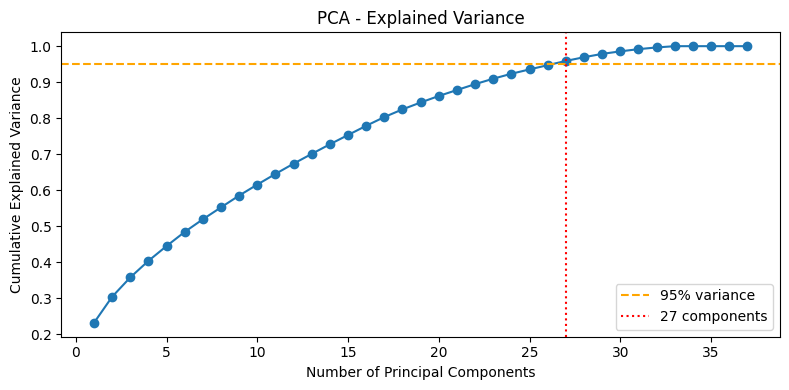

95% variance ke liye components: 27


In [4]:
from sklearn.decomposition import PCA

pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = np.argmax(cum_var >= 0.95) + 1

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o')
plt.axhline(0.95, color='orange', linestyle='--', label='95% variance')
plt.axvline(n_95, color='red', linestyle=':', label=f'{n_95} components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Explained Variance')
plt.legend()
plt.tight_layout()
plt.savefig('pca_variance.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"95% variance ke liye components: {n_95}")

In [5]:
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)
print("Har component ki variance:", pca.explained_variance_ratio_.round(3))
print("3 components ki total variance:", round(pca.explained_variance_ratio_.sum(), 3))

PCA shape: (2236, 3)
Har component ki variance: [0.232 0.072 0.054]
3 components ki total variance: 0.358


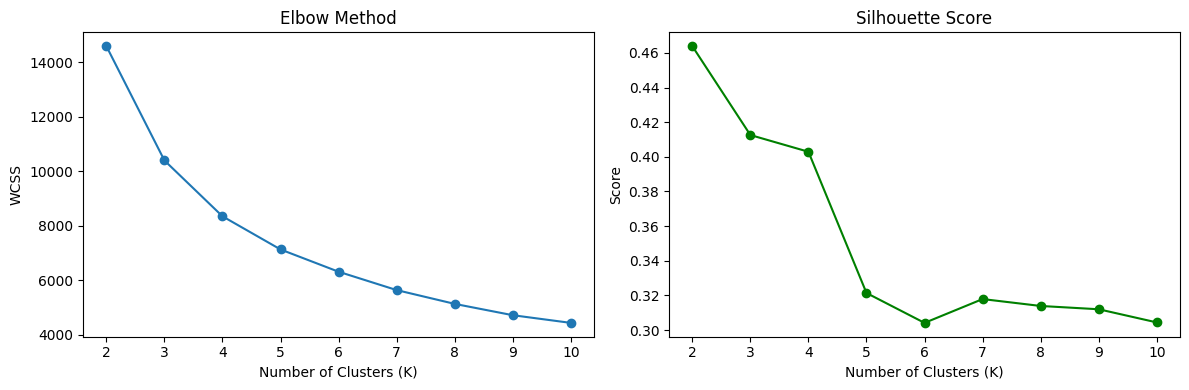

K=2:  WCSS=14,582   Silhouette=0.464
K=3:  WCSS=10,389   Silhouette=0.413
K=4:  WCSS=8,340   Silhouette=0.403
K=5:  WCSS=7,124   Silhouette=0.321
K=6:  WCSS=6,307   Silhouette=0.304
K=7:  WCSS=5,634   Silhouette=0.318
K=8:  WCSS=5,127   Silhouette=0.314
K=9:  WCSS=4,712   Silhouette=0.312
K=10:  WCSS=4,431   Silhouette=0.304


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

K_range = range(2, 11)
wcss = []
sil_scores = []

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_pca)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(K_range, wcss, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('WCSS')

axes[1].plot(K_range, sil_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.savefig('elbow_silhouette.png', dpi=200, bbox_inches='tight')
plt.show()

for k, w, s in zip(K_range, wcss, sil_scores):
    print(f"K={k}:  WCSS={w:,.0f}   Silhouette={s:.3f}")

In [7]:
# 3 se 6 ke beech best Silhouette wala K
scores_3_6 = {k: s for k, s in zip(K_range, sil_scores) if 3 <= k <= 6}
best_k = max(scores_3_6, key=scores_3_6.get)
print("Chosen K:", best_k, "| Silhouette:", round(scores_3_6[best_k], 3))

# Final model
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_pca)

print("\nCustomers per cluster:")
print(df['Cluster'].value_counts().sort_index())

Chosen K: 3 | Silhouette: 0.413

Customers per cluster:
Cluster
0     558
1    1049
2     629
Name: count, dtype: int64


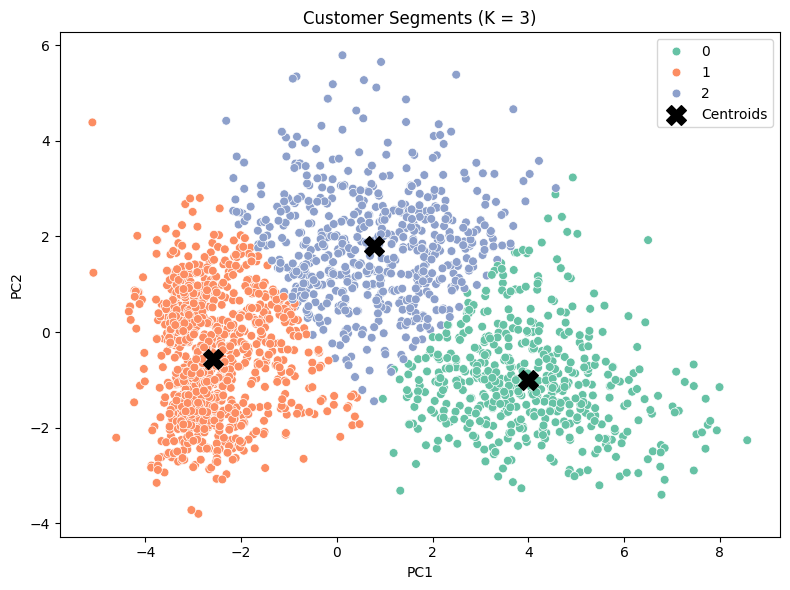

In [8]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['Cluster'], palette='Set2', s=40)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c='black', s=200, marker='X', label='Centroids')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title(f'Customer Segments (K = {best_k})')
plt.legend()
plt.tight_layout()
plt.savefig('clusters.png', dpi=200, bbox_inches='tight')
plt.show()

In [9]:
profile = df.groupby('Cluster')[['Age', 'Income', 'Children', 'TotalSpent',
                                 'TotalPurchases', 'NumWebPurchases', 'NumStorePurchases',
                                 'NumDealsPurchases', 'NumWebVisitsMonth', 'Recency']].mean().round(1)
profile['Customers'] = df['Cluster'].value_counts().sort_index()
profile

,Age,Income,Children,TotalSpent,TotalPurchases,NumWebPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,Recency,Customers
Cluster,,,,,,,,,,,
0,57.3,76166.1,0.2,1397.6,20.8,5.2,8.4,1.2,2.8,49.1,558
1,54.4,35148.8,1.2,100.5,8.0,2.1,3.2,2.0,6.4,49.3,1049
2,61.6,58496.5,1.2,746.8,21.1,6.4,7.8,3.8,5.7,48.8,629


/tmp/ipykernel_3322/1020183005.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Persona', y=col, ax=ax, palette='Set2', errorbar=None)
/tmp/ipykernel_3322/1020183005.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Persona', y=col, ax=ax, palette='Set2', errorbar=None)
/tmp/ipykernel_3322/1020183005.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Persona', y=col, ax=ax, palette='Set2', errorbar=None)


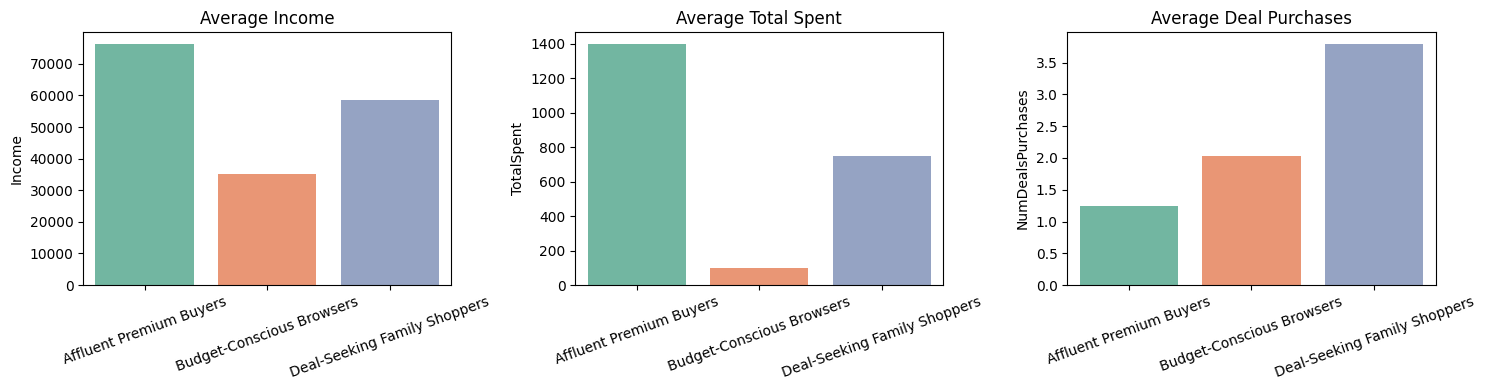

In [10]:
persona_names = {0: 'Affluent Premium Buyers',
                 1: 'Budget-Conscious Browsers',
                 2: 'Deal-Seeking Family Shoppers'}
df['Persona'] = df['Cluster'].map(persona_names)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ['Income', 'TotalSpent', 'NumDealsPurchases'],
                          ['Average Income', 'Average Total Spent', 'Average Deal Purchases']):
    sns.barplot(data=df, x='Persona', y=col, ax=ax, palette='Set2', errorbar=None)
    ax.set_title(title); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig('personas.png', dpi=200, bbox_inches='tight')
plt.show()

In [11]:
from google.colab import files
for f in ['pca_variance.png', 'elbow_silhouette.png', 'clusters.png', 'personas.png']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>